# Policy Metadata Exploration: L24 Patch CKA

This notebook mirrors `policy_metadata_explore.ipynb`, but uses adjacent-frame patch-token `cka_L24_mean` as the target instead of global cosine `similarity_L24_mean`.

The CKA table is computed from detector patch/grid feature maps shaped `[B, N_cam, C, H, W]`. For the current EVA/RepDETR3D path, CLS/register tokens are not present in these maps; this is patch-only CKA.

Outputs are saved under `outputs/policy_signal_stats/val/explore_cka_l24/`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score, log_loss, mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "outputs/policy_signal_stats/val"
EXPLORE_DIR = DATA_DIR / "explore_cka_l24"
EXPLORE_DIR.mkdir(parents=True, exist_ok=True)

META_CSV = DATA_DIR / "policy_signal_stats.csv"
SIM_CSV = DATA_DIR / "policy_feature_similarity.csv"
CKA_CSV = DATA_DIR / "policy_feature_cka_l24.csv"
TARGET = "cka_L24_mean"
META_CSV, SIM_CSV, CKA_CSV, EXPLORE_DIR


(PosixPath('/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/policy_signal_stats.csv'),
 PosixPath('/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/policy_feature_similarity.csv'),
 PosixPath('/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/policy_feature_cka_l24.csv'),
 PosixPath('/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24'))

## Load And Join Tables

Scene starts are removed because adjacent-frame CKA is undefined there. Difficulty labels are quantile-based for CKA because the cosine thresholds `0.65/0.80` are not meaningful on this patch-CKA scale.


In [2]:
meta = pd.read_csv(META_CSV)
sim = pd.read_csv(SIM_CSV)
cka = pd.read_csv(CKA_CSV)

cka_cols = ["token", "scene_token", "has_previous_frame"] + [c for c in cka.columns if c.startswith("cka_L24")]
df = meta.merge(sim, on=["token", "scene_token"], suffixes=("", "_sim"))
df = df.merge(cka[cka_cols], on=["token", "scene_token"], suffixes=("", "_cka"))
df = df[(df["has_previous_frame"] == 1) & df[TARGET].notna()].copy()
df = df.sort_values(["scene_token", "frame_number"]).reset_index(drop=True)

df["cka_L24_drift"] = 1.0 - df[TARGET]
q25, q75 = df[TARGET].quantile([0.25, 0.75])
df["difficulty"] = pd.cut(
    df[TARGET],
    bins=[-np.inf, q25, q75, np.inf],
    labels=["hard", "medium", "easy"],
)

print(f"rows: {len(df)}")
print(f"scenes: {df.scene_token.nunique()}")
print(f"CKA difficulty thresholds: hard < {q25:.6f}; easy >= {q75:.6f}")
df[["token", "scene_token", "frame_number", TARGET, "cka_L24_min", "cka_L24_max", "cka_L24_spread", "difficulty"]].head()


rows: 5869
scenes: 150
CKA difficulty thresholds: hard < 0.060091; easy >= 0.108677


,token,scene_token,frame_number,cka_L24_mean,cka_L24_min,cka_L24_max,cka_L24_spread,difficulty
0,0f5cbb909e9544dd861dc2ff63ac4d13,01452fbfbf4543af8acdfd3e8a1ee806,1,0.557287,0.395182,0.665220,0.270039,easy
1,da74550a10a8408299d7e6b1735963ae,01452fbfbf4543af8acdfd3e8a1ee806,2,0.588303,0.381097,0.739467,0.358371,easy
2,cf86af90b622499b8214df0024a6ea29,01452fbfbf4543af8acdfd3e8a1ee806,3,0.561398,0.402150,0.660796,0.258646,easy
3,901cfd30cb2a4fdba55095f9ec0fed34,01452fbfbf4543af8acdfd3e8a1ee806,4,0.537064,0.384642,0.617977,0.233335,easy
4,5c9d217c4af14c608c7b5f9469dd488b,01452fbfbf4543af8acdfd3e8a1ee806,5,0.541862,0.319854,0.656140,0.336286,easy


## Feature Sets

Online metadata excludes GT/object-derived annotation counts, object distances/sizes/velocities, camera annotation counts, 2D box areas, and new/disappeared object proxies. L8 features are still the cosine L8 probe columns from `policy_feature_similarity.csv`.


In [3]:
ONLINE_METADATA = [
    "frame_number", "info_frame_idx", "is_scene_start", "dt_s",
    "ego_x_m", "ego_y_m", "ego_z_m", "ego_yaw_deg",
    "delta_ego_translation_m", "ego_speed_mps", "ego_accel_mps2",
    "yaw_rate_deg_s", "abs_yaw_rate_deg_s", "yaw_accel_deg_s2", "abs_yaw_accel_deg_s2",
]
NON_FEATURE = {"index", "token", "scene_token", "timestamp", "has_previous_frame", "similarity_L24_mean", "l24_drift"}
OFFLINE_METADATA = [c for c in meta.columns if c not in NON_FEATURE and pd.api.types.is_numeric_dtype(meta[c])]
L8_FEATURES = [c for c in df.columns if c.startswith("similarity_L8_")]
FEATURE_SETS = {
    "metadata_online": ONLINE_METADATA,
    "metadata_offline": OFFLINE_METADATA,
    "metadata_online_plus_L8": ONLINE_METADATA + L8_FEATURES,
    "metadata_offline_plus_L8": OFFLINE_METADATA + L8_FEATURES,
}
pd.DataFrame({"feature_set": FEATURE_SETS.keys(), "n_features": [len(v) for v in FEATURE_SETS.values()]})


,feature_set,n_features
0,metadata_online,15
1,metadata_offline,42
2,metadata_online_plus_L8,22
3,metadata_offline_plus_L8,49


# Stage A: Exploratory Separability

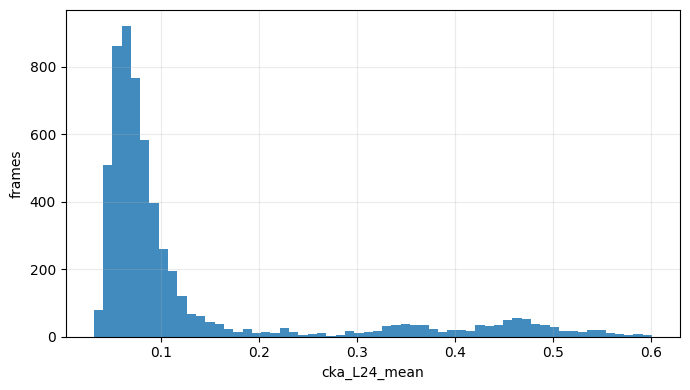

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/cka_L24_mean_distribution.png


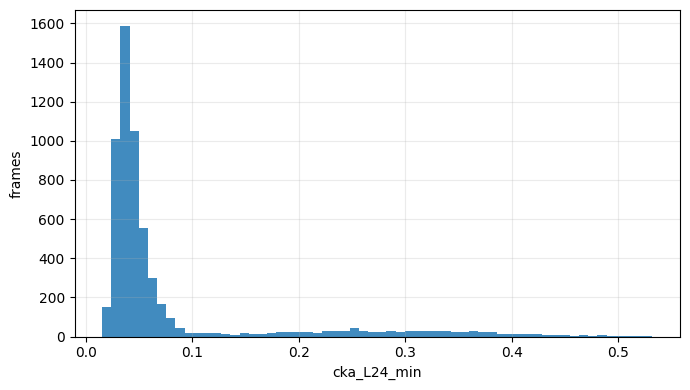

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/cka_L24_min_distribution.png


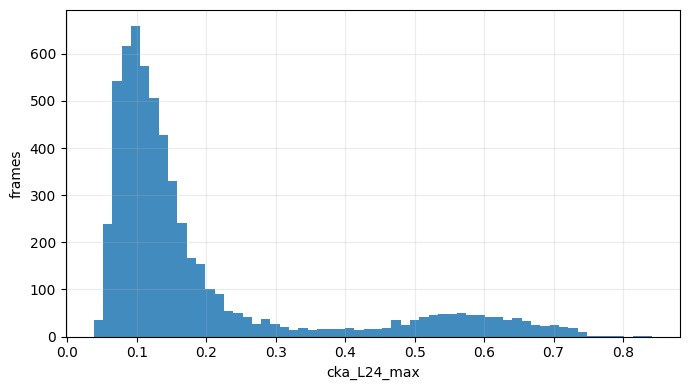

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/cka_L24_max_distribution.png


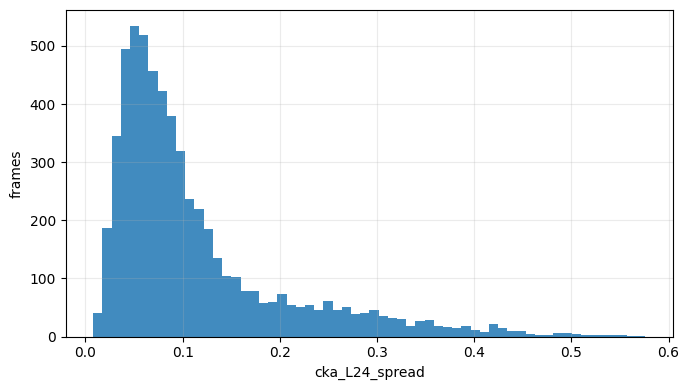

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/cka_L24_spread_distribution.png


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
cka_L24_mean,5869.0,0.127956,0.128263,0.031454,0.039795,0.046422,0.060091,0.076025,0.108677,0.464770,0.541528,0.600614
cka_L24_min,5869.0,0.078304,0.093968,0.015015,0.021261,0.025478,0.033911,0.042139,0.058907,0.326538,0.423509,0.532383
cka_L24_max,5869.0,0.192091,0.168777,0.037640,0.052956,0.065139,0.091914,0.124306,0.189799,0.609842,0.708859,0.841889
cka_L24_spread,5869.0,0.113787,0.092041,0.008029,0.019470,0.029240,0.053074,0.082259,0.135530,0.318001,0.433285,0.576222
similarity_L24_mean,5869.0,0.735372,0.093279,0.488029,0.563217,0.608895,0.674360,0.717835,0.772030,0.934020,0.947919,0.959062


Spearman CKA mean vs cosine L24 mean: 0.501036684978267


In [4]:
def savefig(name):
    path = EXPLORE_DIR / name
    plt.tight_layout()
    plt.savefig(path, dpi=160)
    plt.show()
    print(path)

for col in ["cka_L24_mean", "cka_L24_min", "cka_L24_max", "cka_L24_spread"]:
    plt.figure(figsize=(7, 4))
    plt.hist(df[col].dropna(), bins=60, alpha=0.85)
    plt.xlabel(col)
    plt.ylabel("frames")
    plt.grid(alpha=0.25)
    savefig(f"{col}_distribution.png")

display(df[["cka_L24_mean", "cka_L24_min", "cka_L24_max", "cka_L24_spread", "similarity_L24_mean"]].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T)
print("Spearman CKA mean vs cosine L24 mean:", df[["cka_L24_mean", "similarity_L24_mean"]].corr(method="spearman").iloc[0, 1])


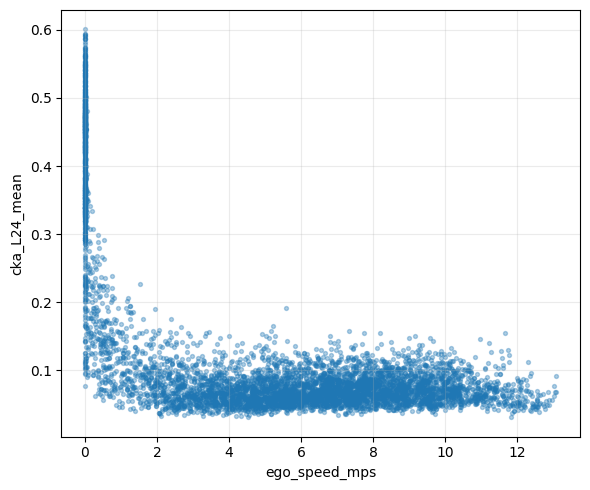

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/speed_vs_cka_l24_mean.png


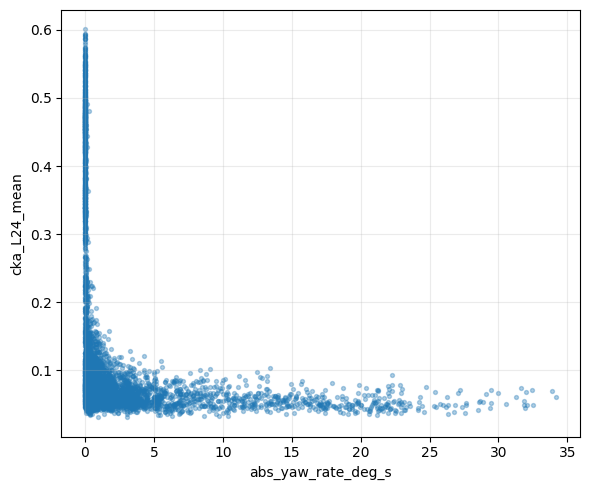

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/yaw_rate_vs_cka_l24_mean.png


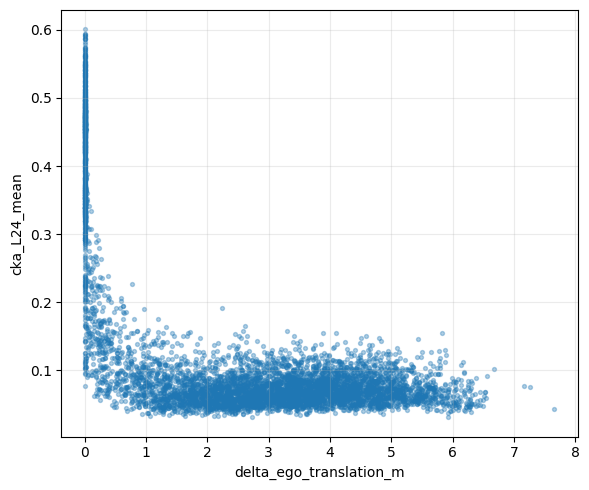

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/delta_translation_vs_cka_l24_mean.png


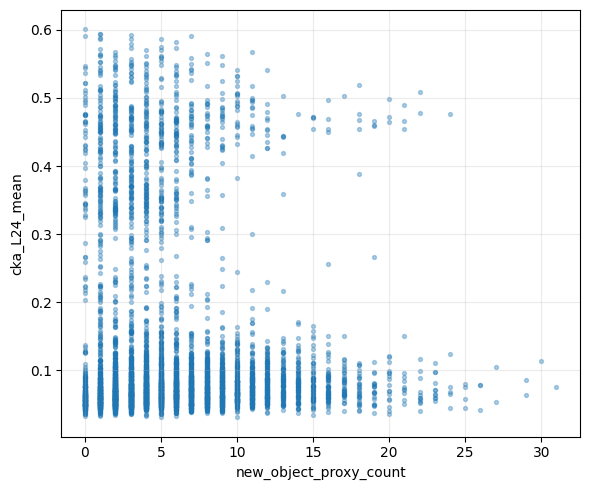

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/new_proxy_vs_cka_l24_mean.png


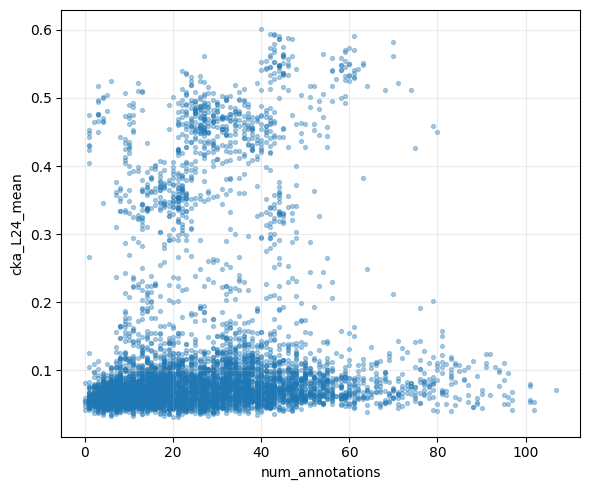

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/num_annotations_vs_cka_l24_mean.png


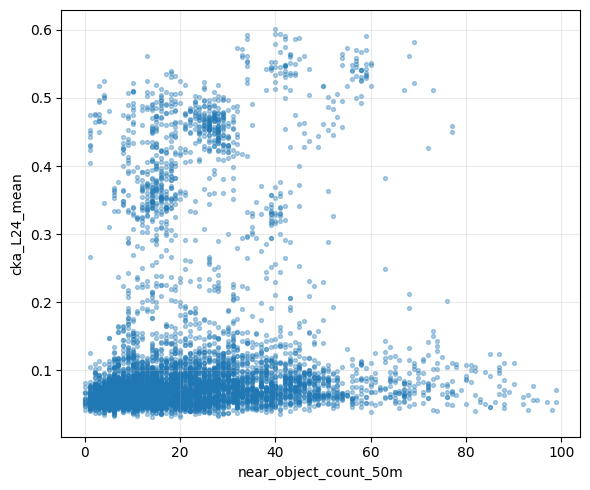

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/near50_vs_cka_l24_mean.png


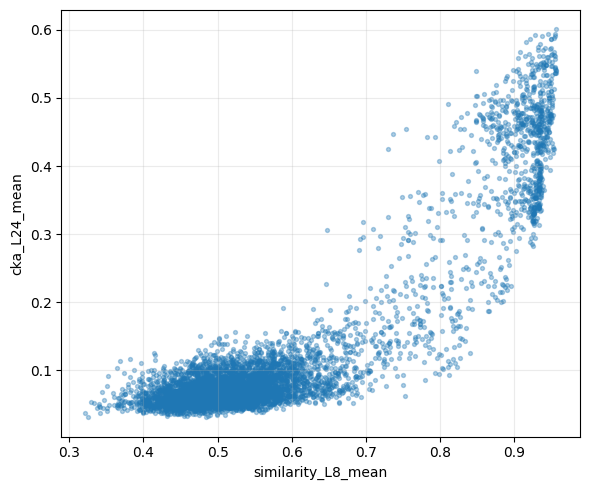

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/l8_mean_vs_cka_l24_mean.png


In [5]:
scatter_specs = [
    ("ego_speed_mps", TARGET, "speed_vs_cka_l24_mean.png"),
    ("abs_yaw_rate_deg_s", TARGET, "yaw_rate_vs_cka_l24_mean.png"),
    ("delta_ego_translation_m", TARGET, "delta_translation_vs_cka_l24_mean.png"),
    ("new_object_proxy_count", TARGET, "new_proxy_vs_cka_l24_mean.png"),
    ("num_annotations", TARGET, "num_annotations_vs_cka_l24_mean.png"),
    ("near_object_count_50m", TARGET, "near50_vs_cka_l24_mean.png"),
    ("similarity_L8_mean", TARGET, "l8_mean_vs_cka_l24_mean.png"),
]
for x, y, name in scatter_specs:
    if x not in df.columns or y not in df.columns:
        continue
    plt.figure(figsize=(6, 5))
    plt.scatter(df[x], df[y], s=8, alpha=0.35)
    plt.xlabel(x)
    plt.ylabel(y)
    plt.grid(alpha=0.25)
    savefig(name)


,frames
difficulty,
hard,1468
medium,2934
easy,1467


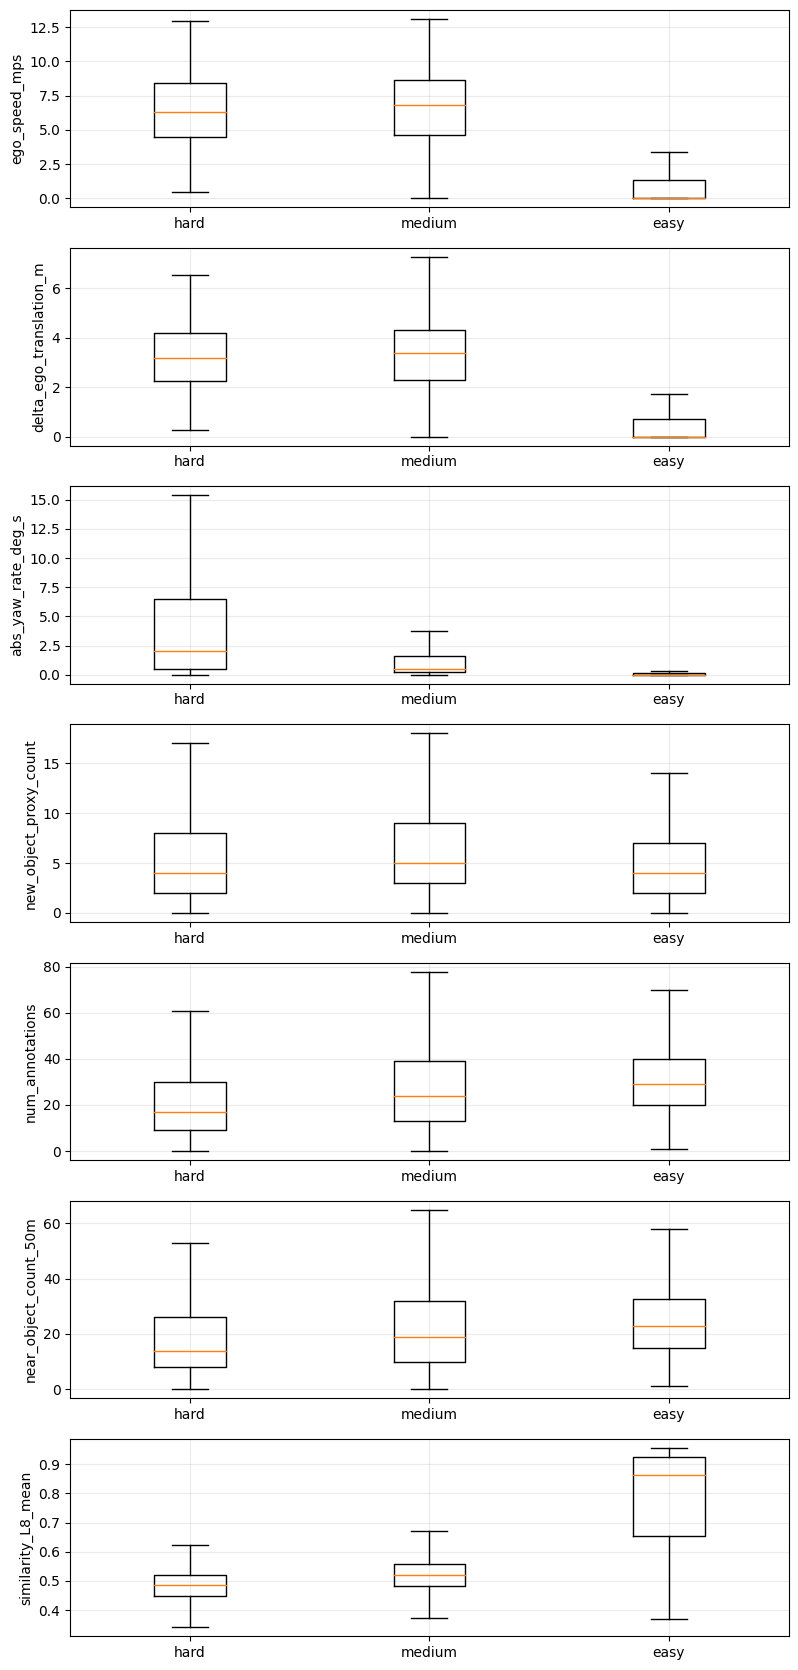

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/cka_difficulty_feature_boxplots.png


In [6]:
display(df["difficulty"].value_counts().reindex(["hard", "medium", "easy"]).to_frame("frames"))
features_for_labels = ["ego_speed_mps", "delta_ego_translation_m", "abs_yaw_rate_deg_s", "new_object_proxy_count", "num_annotations", "near_object_count_50m", "similarity_L8_mean"]
features_for_labels = [c for c in features_for_labels if c in df.columns]
fig, axes = plt.subplots(len(features_for_labels), 1, figsize=(8, 2.4 * len(features_for_labels)))
if len(features_for_labels) == 1:
    axes = [axes]
for ax, col in zip(axes, features_for_labels):
    groups = [df.loc[df["difficulty"] == label, col].dropna() for label in ["hard", "medium", "easy"]]
    ax.boxplot(groups, labels=["hard", "medium", "easy"], showfliers=False)
    ax.set_ylabel(col)
    ax.grid(alpha=0.25)
savefig("cka_difficulty_feature_boxplots.png")


,cka_L24_mean
abs_yaw_rate_deg_s,-0.650821
delta_ego_translation_m,-0.465408
ego_speed_mps,-0.462676
new_object_proxy_count,0.026970
near_object_count_50m,0.228265
camera_annotation_count,0.239296
num_annotations,0.240846
similarity_L24_mean,0.501037
similarity_L8_mean,0.673241
cka_L24_min,0.807317


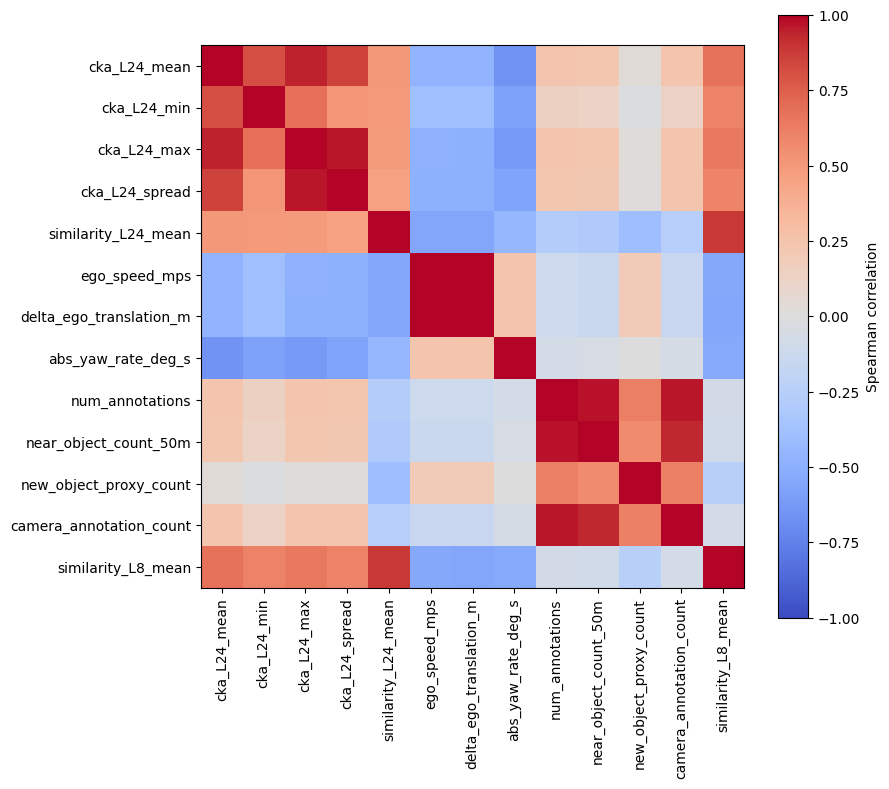

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/cka_stage_a_spearman_correlation_matrix.png


In [7]:
corr_cols = [TARGET, "cka_L24_min", "cka_L24_max", "cka_L24_spread", "similarity_L24_mean", "ego_speed_mps", "delta_ego_translation_m", "abs_yaw_rate_deg_s", "num_annotations", "near_object_count_50m", "new_object_proxy_count", "camera_annotation_count", "similarity_L8_mean"]
corr_cols = [c for c in corr_cols if c in df.columns]
corr = df[corr_cols].corr(method="spearman")
display(corr[[TARGET]].sort_values(TARGET))
plt.figure(figsize=(9, 8))
plt.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(corr_cols)), corr_cols, rotation=90)
plt.yticks(range(len(corr_cols)), corr_cols)
savefig("cka_stage_a_spearman_correlation_matrix.png")


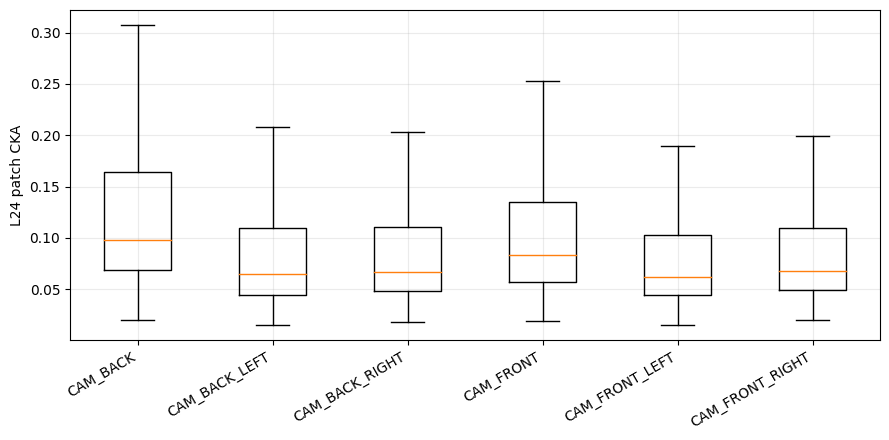

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/per_camera_l24_cka_boxplot.png


,worst_CKA_frames
camera,
CAM_BACK_LEFT,1377
CAM_FRONT_LEFT,1339
CAM_BACK_RIGHT,1161
CAM_FRONT_RIGHT,1032
CAM_FRONT,700
CAM_BACK,260


In [8]:
cka_cam_cols = [c for c in df.columns if c.startswith("cka_L24_CAM_")]
plt.figure(figsize=(9, 4.5))
plt.boxplot([df[c].dropna() for c in cka_cam_cols], labels=[c.replace("cka_L24_", "") for c in cka_cam_cols], showfliers=False)
plt.ylabel("L24 patch CKA")
plt.xticks(rotation=30, ha="right")
plt.grid(alpha=0.25)
savefig("per_camera_l24_cka_boxplot.png")
worst_cka_camera = df[cka_cam_cols].idxmin(axis=1).str.replace("cka_L24_", "", regex=False)
display(worst_cka_camera.value_counts().rename_axis("camera").to_frame("worst_CKA_frames"))


# Stage B: Grouped CV Regression

In [9]:
def evaluate_feature_set(features, target=TARGET, n_splits=5, permutation=False):
    rows = []
    importances = []
    splitter = GroupKFold(n_splits=n_splits)
    for fold, (train_idx, test_idx) in enumerate(splitter.split(df[features], df[target], df["scene_token"]), 1):
        model = make_pipeline(SimpleImputer(strategy="median"), HistGradientBoostingRegressor(random_state=fold))
        model.fit(df.iloc[train_idx][features], df.iloc[train_idx][target])
        pred = model.predict(df.iloc[test_idx][features])
        rows.append({"fold": fold, "r2": r2_score(df.iloc[test_idx][target], pred), "mae": mean_absolute_error(df.iloc[test_idx][target], pred)})
        if permutation:
            pi = permutation_importance(model, df.iloc[test_idx][features], df.iloc[test_idx][target], scoring="neg_mean_absolute_error", n_repeats=10, random_state=100 + fold, n_jobs=1)
            importances.append(pi.importances_mean)
    result = pd.DataFrame(rows)
    importance = pd.Series(np.vstack(importances).mean(axis=0), index=features).sort_values(ascending=False) if permutation else None
    return result, importance

summary_rows = []
importance_tables = {}
for name, features in FEATURE_SETS.items():
    fold_result, importance = evaluate_feature_set(features, permutation=True)
    importance_tables[name] = importance
    summary_rows.append({
        "feature_set": name,
        "n_features": len(features),
        "r2_mean": fold_result["r2"].mean(),
        "r2_std": fold_result["r2"].std(ddof=0),
        "mae_mean": fold_result["mae"].mean(),
        "mae_std": fold_result["mae"].std(ddof=0),
    })
summary = pd.DataFrame(summary_rows).sort_values("mae_mean")
display(summary)
summary.to_csv(EXPLORE_DIR / "stage_b_grouped_cv_cka_summary.csv", index=False)


,feature_set,n_features,r2_mean,r2_std,mae_mean,mae_std
3,metadata_offline_plus_L8,49,0.943131,0.022947,0.017293,0.001843
2,metadata_online_plus_L8,22,0.932985,0.017099,0.019731,0.001453
1,metadata_offline,42,0.875329,0.062173,0.022070,0.001641
0,metadata_online,15,0.889064,0.036659,0.023059,0.000845


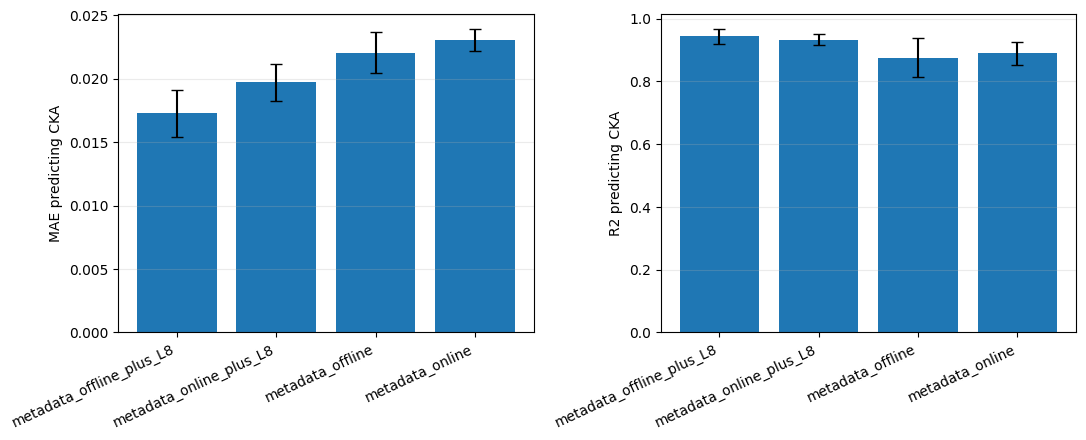

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore_cka_l24/stage_b_cka_feature_set_metrics.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
order = summary["feature_set"].tolist()
x = np.arange(len(order))
for ax, metric, err, ylabel in [(axes[0], "mae_mean", "mae_std", "MAE predicting CKA"), (axes[1], "r2_mean", "r2_std", "R2 predicting CKA")]:
    vals = summary.set_index("feature_set").loc[order, metric]
    yerr = summary.set_index("feature_set").loc[order, err]
    ax.bar(x, vals)
    ax.errorbar(x, vals, yerr=yerr, fmt="none", color="black", capsize=4)
    ax.set_xticks(x)
    ax.set_xticklabels(order, rotation=25, ha="right")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)
savefig("stage_b_cka_feature_set_metrics.png")


In [11]:
for name, importance in importance_tables.items():
    print()
    print(name)
    display(importance.head(12).rename("heldout_MAE_delta").to_frame())



metadata_online


,heldout_MAE_delta
delta_ego_translation_m,3.904215e-02
ego_speed_mps,1.443880e-02
abs_yaw_rate_deg_s,6.900504e-03
ego_y_m,4.866387e-03
ego_yaw_deg,3.714872e-03
abs_yaw_accel_deg_s2,1.565444e-03
ego_x_m,1.546955e-03
ego_accel_mps2,2.511334e-04
info_frame_idx,0.000000e+00
is_scene_start,0.000000e+00



metadata_offline


,heldout_MAE_delta
delta_ego_translation_m,0.037833
ego_speed_mps,0.012387
abs_yaw_rate_deg_s,0.007086
ego_y_m,0.002873
abs_yaw_accel_deg_s2,0.002047
max_2d_box_area_px,0.001596
ego_yaw_deg,0.001406
near_object_count_20m,0.000911
min_object_distance_m,0.000764
avg_box_width_m,0.000667



metadata_online_plus_L8


,heldout_MAE_delta
similarity_L8_CAM_BACK,0.012348
similarity_L8_mean,0.009228
delta_ego_translation_m,0.006641
similarity_L8_CAM_FRONT,0.005458
similarity_L8_CAM_BACK_RIGHT,0.005308
ego_speed_mps,0.005153
ego_yaw_deg,0.002248
ego_y_m,0.002087
abs_yaw_rate_deg_s,0.001205
similarity_L8_CAM_BACK_LEFT,0.001183



metadata_offline_plus_L8


,heldout_MAE_delta
similarity_L8_mean,0.016905
similarity_L8_CAM_BACK,0.010013
delta_ego_translation_m,0.008374
ego_speed_mps,0.004222
similarity_L8_CAM_BACK_RIGHT,0.003847
similarity_L8_CAM_FRONT,0.003344
similarity_L8_CAM_FRONT_RIGHT,0.001930
max_2d_box_area_px,0.001297
ego_yaw_deg,0.001139
abs_yaw_rate_deg_s,0.000909


# Stage C: Difficulty Classification

In [12]:
CLASS_LABELS = ["hard", "medium", "easy"]

def make_classifier(algorithm, fold):
    if algorithm == "hist_gradient_boosting":
        return make_pipeline(SimpleImputer(strategy="median"), HistGradientBoostingClassifier(random_state=fold))
    if algorithm == "small_mlp_softmax":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), MLPClassifier(hidden_layer_sizes=(32,), activation="relu", solver="adam", alpha=1e-4, batch_size=256, learning_rate_init=1e-3, max_iter=300, early_stopping=True, n_iter_no_change=15, random_state=fold))
    raise ValueError(f"unknown algorithm: {algorithm}")

def aligned_proba(model, x, labels=CLASS_LABELS):
    proba = model.predict_proba(x)
    classes = list(model.classes_ if hasattr(model, "classes_") else model[-1].classes_)
    out = np.zeros((len(x), len(labels)), dtype=float)
    for src_idx, cls in enumerate(classes):
        out[:, labels.index(cls)] = proba[:, src_idx]
    return out

def evaluate_classifier(features, algorithm, n_splits=5):
    rows = []
    confusion = np.zeros((len(CLASS_LABELS), len(CLASS_LABELS)), dtype=int)
    y = df["difficulty"].astype(str)
    for fold, (train_idx, test_idx) in enumerate(GroupKFold(n_splits=n_splits).split(df[features], y, df["scene_token"]), 1):
        model = make_classifier(algorithm, fold)
        model.fit(df.iloc[train_idx][features], y.iloc[train_idx])
        x_test = df.iloc[test_idx][features]
        y_test = y.iloc[test_idx]
        pred = model.predict(x_test)
        proba = aligned_proba(model, x_test)
        confusion += confusion_matrix(y_test, pred, labels=CLASS_LABELS)
        rows.append({
            "fold": fold,
            "cross_entropy": log_loss(y_test, proba, labels=CLASS_LABELS),
            "accuracy": accuracy_score(y_test, pred),
            "balanced_accuracy": balanced_accuracy_score(y_test, pred),
            "macro_f1": f1_score(y_test, pred, labels=CLASS_LABELS, average="macro"),
        })
    return pd.DataFrame(rows), pd.DataFrame(confusion, index=CLASS_LABELS, columns=CLASS_LABELS)


In [13]:
classification_rows = []
classification_confusions = {}
for feature_set_name, features in FEATURE_SETS.items():
    for algorithm in ["hist_gradient_boosting", "small_mlp_softmax"]:
        fold_result, confusion = evaluate_classifier(features, algorithm)
        classification_confusions[f"{feature_set_name}__{algorithm}"] = confusion
        classification_rows.append({
            "feature_set": feature_set_name,
            "algorithm": algorithm,
            "n_features": len(features),
            "cross_entropy_mean": fold_result["cross_entropy"].mean(),
            "cross_entropy_std": fold_result["cross_entropy"].std(ddof=0),
            "balanced_accuracy_mean": fold_result["balanced_accuracy"].mean(),
            "macro_f1_mean": fold_result["macro_f1"].mean(),
        })
classification_summary = pd.DataFrame(classification_rows).sort_values("cross_entropy_mean")
display(classification_summary)
classification_summary.to_csv(EXPLORE_DIR / "stage_c_cka_difficulty_classification_summary.csv", index=False)


,feature_set,algorithm,n_features,cross_entropy_mean,cross_entropy_std,balanced_accuracy_mean,macro_f1_mean
1,metadata_online,small_mlp_softmax,15,2.872652,0.426602,0.651894,0.658229
3,metadata_offline,small_mlp_softmax,42,3.466061,0.766542,0.689408,0.697511
5,metadata_online_plus_L8,small_mlp_softmax,22,4.250836,0.881698,0.677576,0.693857
0,metadata_online,hist_gradient_boosting,15,5.123397,0.373928,0.668350,0.683124
2,metadata_offline,hist_gradient_boosting,42,5.466631,0.344450,0.698875,0.715935
7,metadata_offline_plus_L8,small_mlp_softmax,49,5.670579,0.908257,0.737132,0.750002
4,metadata_online_plus_L8,hist_gradient_boosting,22,5.872630,0.378379,0.686003,0.701168
6,metadata_offline_plus_L8,hist_gradient_boosting,49,6.554921,0.281372,0.733927,0.751059


In [14]:
for key, confusion in classification_confusions.items():
    print(key)
    display(confusion)


metadata_online__hist_gradient_boosting


,hard,medium,easy
hard,646,817,5
medium,457,2354,123
easy,16,329,1122


metadata_online__small_mlp_softmax


,hard,medium,easy
hard,475,983,10
medium,298,2441,195
easy,6,299,1162


metadata_offline__hist_gradient_boosting


...

,hard,medium,easy
hard,633,835,0
medium,392,2429,113
easy,9,325,1133


metadata_offline_plus_L8__hist_gradient_boosting


,hard,medium,easy
hard,818,650,0
medium,340,2491,103
easy,0,297,1170


metadata_offline_plus_L8__small_mlp_softmax


,hard,medium,easy
hard,855,613,0
medium,387,2409,138
easy,0,271,1196
